# Práctica de Deep Learning para Finanzas · Avance 3 (capítulo 9)
**Ciencia de Datos Aplicada a la Economía** · Prof. Rubén Miguel Rodríguez Rangel · Luis Enrique López Salazar

Tema: validación temporal, umbrales y señal. ¿Los resultados se sostienen a lo largo del tiempo?

Entregable (protocolo §5): errores por ventana, umbrales probados y regla seleccionada. **TE no interviene en ninguna decisión:**
sus filas se descartan en la celda 4, antes de cualquier ajuste.

**Cómo correrlo:** en Colab o en cualquier Python 3 (no necesita GPU). *Ejecutar todas*; la celda 2 pide subir `avance3_insumos.zip`.

## 1. Configuración y versiones

In [1]:
import json, os, platform, shutil, sys
import numpy as np, pandas as pd, matplotlib, sklearn
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEMILLA = 42
VENTANA = 20
BLOQUES_TR = 4                 # TR en 4 bloques contiguos: 3 evaluaciones con ventana expansiva
UMBRALES = [0.0005, 0.001, 0.002, 0.003, 0.005]   # δ predefinidos y positivos (rendimiento simple diario estimado)
CAPITAL, COSTO = 100_000, 0.001                    # protocolo §9: 100,000 USDT y 0.10 % por compra y por venta
EN_COLAB = "google.colab" in sys.modules
for d in ["data/processed", "outputs", "figures"]:
    os.makedirs(d, exist_ok=True)
VERSIONES = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
             "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__}
print(VERSIONES, "| semilla", SEMILLA)

{'python': '3.12.3', 'numpy': '2.5.5', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'} | semilla 42


## 2. Insumos de los Avances 1 y 2

In [2]:
INSUMOS = ["data/processed/ventanas_btcusdt_1d.csv", "data/processed/btcusdt_1d_auditado.csv", "outputs/particiones_avance1.csv",
           "outputs/seleccion_avance2.json", "outputs/experimentos_avance2.csv"]
if EN_COLAB and not all(map(os.path.exists, INSUMOS)):
    from google.colab import files
    print("Sube avance3_insumos.zip")
    shutil.unpack_archive(next(iter(files.upload())), ".")
faltan = [f for f in INSUMOS if not os.path.exists(f)]
if faltan:
    raise FileNotFoundError(f"Faltan insumos: {faltan}. Detengo el flujo.")
SELECCION = json.load(open(INSUMOS[3]))
print("Modelo elegido con VA en el Avance 2:", SELECCION["elegido"], f"(corrida: {SELECCION['modo']})")

Modelo elegido con VA en el Avance 2: Regresión lineal (20 rezagos) (corrida: t4)


## 3. Modelo a evaluar
Se usa el modelo que el Avance 2 eligió con VA. Si fue la regresión lineal, se ajusta por mínimos cuadrados.
Si fue una red, se reentrena con la misma arquitectura y el **número de épocas de su mejor época** (semilla 42), sin parada temprana:
dentro de una ventana no hay un VA propio y no se debe mirar el bloque evaluado.

In [3]:
ELEGIDO = SELECCION["elegido"]
RED = "MLP" if ELEGIDO.startswith("MLP") else "LSTM" if ELEGIDO.startswith("LSTM") else None
if RED:
    import torch
    from torch import nn
    exp2 = pd.read_csv(INSUMOS[4])
    cfg = exp2[(exp2.red == RED) & (exp2.semilla == SEMILLA) & (ELEGIDO.split("(")[1].split()[0] == exp2.neuronas.astype(str))].iloc[0]
    NEURONAS, EPOCAS, LR, LOTE = int(cfg.neuronas), int(cfg.mejor_epoca), float(cfg.lr), int(cfg.lote)
    print(f"{RED} con {NEURONAS} neuronas, {EPOCAS} épocas, lr {LR}, lote {LOTE}")
elif not ELEGIDO.startswith("Regresión lineal"):
    raise ValueError(f"Modelo no reconocido: {ELEGIDO}")

def ajustar(Xtr, ytr):
    """Recibe X y y ya escalados con el mismo entrenamiento; devuelve una función que predice y escalada."""
    if RED is None:
        m = LinearRegression().fit(Xtr, ytr)
        return lambda X: m.predict(X).ravel()
    torch.manual_seed(SEMILLA)
    forma = (lambda x: x) if RED == "MLP" else (lambda x: np.ascontiguousarray(x[:, ::-1]).reshape(len(x), VENTANA, 1))
    if RED == "MLP":
        modelo = nn.Sequential(nn.Linear(VENTANA, NEURONAS), nn.ReLU(), nn.Linear(NEURONAS, NEURONAS), nn.ReLU(), nn.Linear(NEURONAS, 1))
    else:
        class LSTM(nn.Module):
            def __init__(self):
                super().__init__()
                self.lstm, self.salida = nn.LSTM(1, NEURONAS, batch_first=True), nn.Linear(NEURONAS, 1)
            def forward(self, x):
                return self.salida(self.lstm(x)[0][:, -1])
        modelo = LSTM()
    xt, yt = torch.tensor(forma(Xtr), dtype=torch.float32), torch.tensor(ytr, dtype=torch.float32).reshape(-1, 1)
    opt, mse, azar = torch.optim.Adam(modelo.parameters(), lr=LR), nn.MSELoss(), torch.Generator().manual_seed(SEMILLA)
    for _ in range(EPOCAS):
        for idx in torch.randperm(len(xt), generator=azar).split(LOTE):
            opt.zero_grad(); mse(modelo(xt[idx]), yt[idx]).backward(); opt.step()
    modelo.eval()
    def predecir(X):
        with torch.no_grad():
            return modelo(torch.tensor(forma(X), dtype=torch.float32)).numpy().ravel()
    return predecir

## 4. Particiones del Avance 1 y reserva de TE
Se comprueban tamaños y fechas contra el Avance 1. Después **se descartan las filas de TE y los precios desde su primera fecha**:
ninguna celda posterior puede usarlas.

In [4]:
datos = pd.read_csv(INSUMOS[0], parse_dates=["fecha_emision", "fecha_objetivo"])
ref = pd.read_csv(INSUMOS[2]).set_index("conjunto")
LAGS = [f"r_lag{i}" for i in range(VENTANA)]
for k in ["TR", "VA", "TE"]:
    p = datos[datos.conjunto == k]
    assert len(p) == ref.loc[k, "ejemplos"], f"{k}: {len(p)} ejemplos ≠ Avance 1"
    assert str(p.fecha_objetivo.min().date()) == ref.loc[k, "primera_fecha_objetivo"], f"{k}: fechas ≠ Avance 1"
INICIO_TE = pd.Timestamp(ref.loc["TE", "primera_fecha_objetivo"])
datos = datos[datos.conjunto != "TE"].sort_values("fecha_objetivo").reset_index(drop=True)
precios = pd.read_csv(INSUMOS[1], parse_dates=["fecha"]).set_index("fecha")
precios = precios[precios.index < INICIO_TE]
assert datos.fecha_objetivo.max() < INICIO_TE and precios.index.max() < INICIO_TE
TR, VA = datos[datos.conjunto == "TR"].reset_index(drop=True), datos[datos.conjunto == "VA"].reset_index(drop=True)
print(f"TR {len(TR)} | VA {len(VA)} | TE descartado ({ref.loc['TE', 'ejemplos']} filas desde {INICIO_TE.date()}); último precio: {precios.index.max().date()}")

TR 2067 | VA 442 | TE descartado (444 filas desde 2025-08-18); último precio: 2025-08-17


## 5. Tres evaluaciones con ventana expansiva dentro de TR
TR se divide en 4 bloques contiguos. La ventana *k* entrena con los bloques 1…*k* y evalúa el bloque *k*+1.
En cada ventana los escaladores se **reajustan solo con su entrenamiento**, y el último objetivo entrenado no pasa de
la primera fecha de emisión del bloque evaluado (era un dato conocido al emitir). La referencia es pronosticar cero.

In [5]:
def metricas(real, est):
    return {"MAE": mean_absolute_error(real, est), "RMSE": mean_squared_error(real, est) ** 0.5,
            "precision_direccional": float(np.mean(np.sign(est[real != 0]) == np.sign(real[real != 0])))}

def entrenar_y_predecir(entreno, evaluar):
    escX, escY = StandardScaler().fit(entreno[LAGS]), StandardScaler().fit(entreno[["y"]])
    predecir = ajustar(escX.transform(entreno[LAGS]), escY.transform(entreno[["y"]]).ravel())
    est = lambda p: escY.inverse_transform(predecir(escX.transform(p[LAGS])).reshape(-1, 1)).ravel()
    return {k: est(p) for k, p in evaluar.items()}, escX.n_samples_seen_

cortes = np.linspace(0, len(TR), BLOQUES_TR + 1).astype(int)
filas = []
for k in range(1, BLOQUES_TR):
    entreno, bloque = TR.iloc[:cortes[k]], TR.iloc[cortes[k]:cortes[k + 1]]
    assert entreno.fecha_objetivo.max() <= bloque.fecha_emision.min(), "el entrenamiento invade el bloque evaluado"
    pred, n_esc = entrenar_y_predecir(entreno, {"bloque": bloque})
    assert n_esc == len(entreno), "escaladores ajustados con datos fuera del entrenamiento"
    real = bloque.y.to_numpy()
    m, c = metricas(real, pred["bloque"]), metricas(real, np.zeros_like(real))
    filas.append({"ventana": k, "entreno_desde": entreno.fecha_objetivo.min().date(), "entreno_hasta": entreno.fecha_objetivo.max().date(),
                  "n_entreno": len(entreno), "evalua_desde": bloque.fecha_objetivo.min().date(),
                  "evalua_hasta": bloque.fecha_objetivo.max().date(), "n_evalua": len(bloque),
                  "MAE": m["MAE"], "RMSE": m["RMSE"], "precision_direccional": m["precision_direccional"],
                  "RMSE_cero": c["RMSE"], "RMSE_vs_cero_%": 100 * (1 - m["RMSE"] / c["RMSE"])})
ventanas = pd.DataFrame(filas)
ventanas.to_csv("outputs/ventanas_expansivas.csv", index=False)
print("Precisión direccional: aciertos de signo entre los días con rendimiento real distinto de cero.")
ventanas.round(5)

Precisión direccional: aciertos de signo entre los días con rendimiento real distinto de cero.


,ventana,entreno_desde,entreno_hasta,n_entreno,evalua_desde,evalua_hasta,n_evalua,MAE,RMSE,precision_direccional,RMSE_cero,RMSE_vs_cero_%
0,1,2018-09-13,2020-03-03,516,2020-03-04,2021-08-02,517,0.02998,0.04507,0.51257,0.04387,-2.73288
1,2,2018-09-13,2021-08-02,1033,2021-08-03,2023-01-01,517,0.02474,0.03485,0.46422,0.03378,-3.15786
2,3,2018-09-13,2023-01-01,1550,2023-01-02,2024-06-01,517,0.01730,0.02549,0.53965,0.02555,0.24090


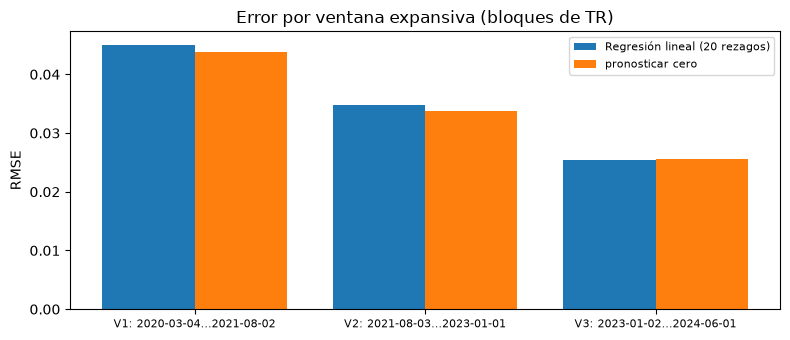

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(len(ventanas))
ax.bar(x - 0.2, ventanas.RMSE, 0.4, label=SELECCION["elegido"]); ax.bar(x + 0.2, ventanas.RMSE_cero, 0.4, label="pronosticar cero")
ax.set_xticks(x, [f"V{r.ventana}: {r.evalua_desde}…{r.evalua_hasta}" for r in ventanas.itertuples()], fontsize=8)
ax.set(ylabel="RMSE", title="Error por ventana expansiva (bloques de TR)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("figures/fig06_ventanas_expansivas.png", dpi=120)

## 6. Modelo final: entrenado con todo TR, estimaciones de VA
Mismo procedimiento con TR completo (escaladores solo con TR). VA sirve para elegir la regla; TE sigue fuera.

In [7]:
pred, n_esc = entrenar_y_predecir(TR, {"TR": TR, "VA": VA})
assert n_esc == len(TR)
VA = VA.assign(estimado=pred["VA"])
VA[["fecha_emision", "fecha_objetivo", "estimado"]].to_csv("outputs/estimados_va.csv", index=False)   # el estado del Avance 4
resumen_va = pd.DataFrame([{"conjunto": k, **metricas(p.y.to_numpy(), pred[k])} for k, p in [("TR", TR), ("VA", VA)]])
print("Estimado en VA: mediana", f"{np.median(pred['VA']):.5f},", "percentil 90", f"{np.quantile(pred['VA'], 0.9):.5f}")
resumen_va.round(5)

Estimado en VA: mediana 0.00169, percentil 90 0.00507


,conjunto,MAE,RMSE,precision_direccional
0,TR,0.02334,0.03489,0.52637
1,VA,0.01728,0.02426,0.50226


## 7. Simulación con cada umbral en VA (reglas del protocolo §9)
- Señal al cierre de *t* (fecha de emisión): **comprar** si el rendimiento estimado supera δ; si no, **efectivo**.
- Se ejecuta en la **apertura de *t*+1** (fecha objetivo). Posición 100 % o 0 %, sin cortos.
- Costo de 0.10 % sobre el monto negociado, en cada compra y cada venta; solo cuando cambia la posición.
- Patrimonio al cierre de cada día; al final se liquida al último cierre de VA cobrando la venta.
- Referencias desde la misma primera ejecución: efectivo y comprar y mantener (con compra y venta cobradas).

In [8]:
def simular(senal, fechas):
    """senal[i] (bool) se emitió al cierre previo a fechas[i] y se ejecuta en su apertura."""
    efectivo, unidades, costos, compra, filas, operaciones = float(CAPITAL), 0.0, 0.0, 0.0, [], []
    for s, f in zip(senal, fechas):
        apertura, cierre = precios.loc[f, "open"], precios.loc[f, "close"]
        if s and unidades == 0:
            unidades = efectivo / (apertura * (1 + COSTO)); costo = unidades * apertura * COSTO
            compra, efectivo, costos = efectivo, 0.0, costos + costo
        elif not s and unidades > 0:
            bruto = unidades * apertura; costo = bruto * COSTO
            efectivo, unidades, costos = bruto - costo, 0.0, costos + costo
            operaciones.append(efectivo - compra)
        filas.append({"fecha": f.date(), "precio_ejecucion": apertura, "senal": "comprar" if s else "efectivo",
                      "posicion": int(unidades > 0), "efectivo": efectivo, "costos_acum": costos, "patrimonio": efectivo + unidades * cierre})
    if unidades > 0:   # liquidación al último cierre
        bruto = unidades * cierre; costo = bruto * COSTO
        efectivo, costos = bruto - costo, costos + costo
        operaciones.append(efectivo - compra)
        filas[-1].update(posicion=0, efectivo=efectivo, costos_acum=costos, patrimonio=efectivo)
    tabla = pd.DataFrame(filas)
    pico = tabla.patrimonio.cummax()
    return tabla, {"rendimiento_neto_%": 100 * (tabla.patrimonio.iloc[-1] / CAPITAL - 1),
                   "max_drawdown_%": 100 * ((tabla.patrimonio - pico) / pico).min(),
                   "operaciones": len(operaciones),
                   "win_rate_%": 100 * np.mean(np.array(operaciones) > 0) if operaciones else np.nan,
                   "dias_invertido_%": 100 * np.mean(senal), "costos_totales": costos}

FECHAS = VA.fecha_objetivo
assert FECHAS.isin(precios.index).all(), "faltan precios de apertura o cierre en VA"
resultados, sims = [], {}
for d in UMBRALES:
    sims[d], r = simular((VA.estimado > d).to_numpy(), FECHAS)
    resultados.append({"estrategia": f"pronóstico > {d:.2%}", "umbral": d, **r})
for nombre, s in [("comprar y mantener", np.ones(len(VA), bool)), ("efectivo", np.zeros(len(VA), bool))]:
    sims[nombre], r = simular(s, FECHAS)
    resultados.append({"estrategia": nombre, "umbral": np.nan, **r})
umbrales = pd.DataFrame(resultados)
umbrales.to_csv("outputs/umbrales_va.csv", index=False)
print("Win Rate vacío (NaN) = no definido: sin operaciones cerradas.")
umbrales.round(4)

Win Rate vacío (NaN) = no definido: sin operaciones cerradas.


,estrategia,umbral,rendimiento_neto_%,max_drawdown_%,operaciones,win_rate_%,dias_invertido_%,costos_totales
0,pronóstico > 0.05%,0.0005,32.5383,-23.4678,101,56.4356,67.1946,20860.2554
1,pronóstico > 0.10%,0.0010,28.4921,-25.1481,107,54.2056,58.3710,22641.5723
2,pronóstico > 0.20%,0.0020,-1.7486,-21.4660,116,50.0000,45.0226,22232.1853
3,pronóstico > 0.30%,0.0030,-6.5378,-17.6109,98,47.9592,31.4480,18633.6797
4,pronóstico > 0.50%,0.0050,-13.9536,-19.8640,44,47.7273,10.8597,7888.9097
5,comprar y mantener,NaN,72.9064,-28.0953,1,100.0000,100.0000,272.9796
6,efectivo,NaN,0.0000,0.0000,0,NaN,0.0000,0.0000


## 8. Regla seleccionada (con VA)
Criterio del protocolo: mayor rendimiento neto en VA; en empate, menor drawdown.

Al cierre de t: comprar (100 %) si el rendimiento estimado para t+1 > 0.05%; si no, efectivo. Ejecutar en la apertura de t+1.
VA: +32.54 % neto, drawdown -23.47 %, 101 operaciones | comprar y mantener: +72.91 %
La regla elegida NO supera a comprar y mantener en VA: con estos costos, el pronóstico no agrega valor frente a quedarse comprado.


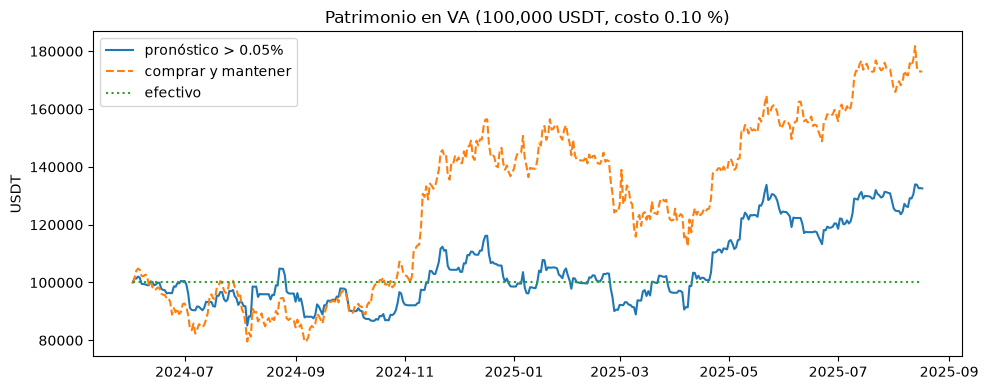

In [9]:
cand = umbrales[umbrales.umbral.notna()].sort_values(["rendimiento_neto_%", "max_drawdown_%"], ascending=[False, False])
mejor = cand.iloc[0]
DELTA = float(mejor.umbral)
sim = sims[DELTA]
sim.to_csv("outputs/simulacion_va.csv", index=False)
cyh = umbrales.set_index("estrategia").loc["comprar y mantener"]
regla = {"regla": f"Al cierre de t: comprar (100 %) si el rendimiento estimado para t+1 > {DELTA:.2%}; si no, efectivo. Ejecutar en la apertura de t+1.",
         "umbral": DELTA, "modelo": SELECCION["elegido"], "elegido_con": "VA (rendimiento neto; empate: menor drawdown)",
         "rendimiento_neto_VA_%": float(mejor["rendimiento_neto_%"]), "max_drawdown_VA_%": float(mejor["max_drawdown_%"]),
         "operaciones_VA": int(mejor.operaciones), "comprar_y_mantener_VA_%": float(cyh["rendimiento_neto_%"]),
         "supera_comprar_y_mantener": bool(mejor["rendimiento_neto_%"] > cyh["rendimiento_neto_%"])}
json.dump(regla, open("outputs/regla_seleccionada.json", "w"), ensure_ascii=False, indent=1)
print(regla["regla"])
print(f"VA: {regla['rendimiento_neto_VA_%']:+.2f} % neto, drawdown {regla['max_drawdown_VA_%']:.2f} %, {regla['operaciones_VA']} operaciones | "
      f"comprar y mantener: {regla['comprar_y_mantener_VA_%']:+.2f} %")
if not regla["supera_comprar_y_mantener"]:
    print("La regla elegida NO supera a comprar y mantener en VA: con estos costos, el pronóstico no agrega valor frente a quedarse comprado.")

fig, ax = plt.subplots(figsize=(10, 4))
for nombre, estilo in [(DELTA, "-"), ("comprar y mantener", "--"), ("efectivo", ":")]:
    t = sims[nombre]
    ax.plot(pd.to_datetime(t.fecha), t.patrimonio, estilo, label=f"pronóstico > {DELTA:.2%}" if nombre == DELTA else nombre)
ax.set(title="Patrimonio en VA (100,000 USDT, costo 0.10 %)", ylabel="USDT"); ax.legend()
fig.tight_layout(); fig.savefig("figures/fig07_patrimonio_va.png", dpi=120)

## 9. Seguimiento: ¿el resultado depende de un único periodo favorable?
Se mira el error por ventana (¿el modelo supera a cero en las tres?) y el rendimiento de la regla por mes de VA,
también sin su mejor mes.

In [10]:
gana = int((ventanas["RMSE_vs_cero_%"] > 0).sum())
print(f"Ventanas expansivas: el modelo supera a pronosticar cero en {gana} de {len(ventanas)} "
      f"(cambio de RMSE: {', '.join(f'{v:+.2f} %' for v in ventanas['RMSE_vs_cero_%'])}).")
p = sim.assign(mes=pd.to_datetime(sim.fecha).dt.to_period("M")).groupby("mes").patrimonio.last()
meses = (p / p.shift(1, fill_value=CAPITAL) - 1).rename("rendimiento_regla").to_frame()
meses.to_csv("outputs/meses_va.csv")
sin_mejor = 100 * ((1 + meses.rendimiento_regla.drop(meses.rendimiento_regla.idxmax())).prod() - 1)
print(f"Meses de VA con rendimiento positivo: {(meses.rendimiento_regla > 0).sum()} de {len(meses)}; "
      f"mejor mes {meses.rendimiento_regla.idxmax()} ({100 * meses.rendimiento_regla.max():+.2f} %).")
print(f"Rendimiento de la regla sin su mejor mes: {sin_mejor:+.2f} % (con él: {regla['rendimiento_neto_VA_%']:+.2f} %).")
if gana < len(ventanas) or sin_mejor <= 0:
    print("Lectura: el resultado NO es estable en el tiempo; depende de periodos concretos. No se debe extrapolar.")
else:
    print("Lectura: el modelo supera a cero en todas las ventanas y la regla sigue positiva sin su mejor mes.")

Ventanas expansivas: el modelo supera a pronosticar cero en 1 de 3 (cambio de RMSE: -2.73 %, -3.16 %, +0.24 %).
Meses de VA con rendimiento positivo: 9 de 15; mejor mes 2025-04 (+15.58 %).
Rendimiento de la regla sin su mejor mes: +14.67 % (con él: +32.54 %).
Lectura: el resultado NO es estable en el tiempo; depende de periodos concretos. No se debe extrapolar.


## 10. Diferenciación fraccionaria (explicación; no se implementa)
**Propósito.** Los modelos funcionan mejor con series estacionarias, pero diferenciar por completo (*d* = 1, pasar de precio a
rendimiento) borra la memoria de largo plazo del nivel de precio. La diferenciación fraccionaria (López de Prado, 2018) aplica
un *d* entre 0 y 1: busca el menor *d* que vuelve estacionaria la serie (prueba ADF) conservando la mayor memoria posible.

**¿Es pertinente aquí?** Poco. Las 20 variables ya son **rendimientos simples** (equivalen a *d* = 1) y el objetivo también.
Sería pertinente si se agregaran variables en **nivel** (precio, volumen acumulado o una SMA en dólares), que no son
estacionarias. En el Avance 5 los indicadores conviene usarlos como razones (cierre / SMA20 − 1, volatilidad de rendimientos),
que ya son estacionarias, así que tampoco la necesitarían.

## 11. Nota sobre el umbral
Un umbral no equivale a una probabilidad de acierto: δ es un nivel del **rendimiento estimado**, no la confianza del modelo.
Que el pronóstico supere 0.20 % no significa que el precio vaya a subir con alguna probabilidad conocida.

## 12. Comprobación final

In [11]:
chk = {
    "3 ventanas expansivas con su error": len(ventanas) == 3 and ventanas[["MAE", "RMSE"]].notna().all().all(),
    "cada entrenamiento termina antes de su bloque": all(
        pd.Timestamp(r.entreno_hasta) < pd.Timestamp(r.evalua_desde) for r in ventanas.itertuples()),
    "el entrenamiento crece en cada ventana": ventanas.n_entreno.is_monotonic_increasing,
    "hasta 5 umbrales positivos predefinidos": 0 < len(UMBRALES) <= 5 and all(u > 0 for u in UMBRALES),
    "regla elegida con VA y guardada": os.path.exists("outputs/regla_seleccionada.json") and DELTA in UMBRALES,
    "simulación en fechas de VA": sim.fecha.min() == VA.fecha_objetivo.min().date() and sim.fecha.max() == VA.fecha_objetivo.max().date(),
    "posición final liquidada": sim.posicion.iloc[-1] == 0,
    "TE sin intervenir (sin filas ni precios de TE)": "TE" not in set(datos.conjunto) and precios.index.max() < INICIO_TE,
    "figuras guardadas": all(os.path.getsize(f) > 10_000 for f in ["figures/fig06_ventanas_expansivas.png", "figures/fig07_patrimonio_va.png"]),
}
for k, v in chk.items():
    print(("OK   " if v else "FALLA ") + k)
json.dump({"modelo": SELECCION["elegido"], "modo_avance2": SELECCION["modo"], "umbral": DELTA, "versiones": VERSIONES,
           "comprobaciones": {k: bool(v) for k, v in chk.items()}}, open("outputs/resumen.json", "w"), ensure_ascii=False, indent=1)

OK   3 ventanas expansivas con su error
OK   cada entrenamiento termina antes de su bloque
OK   el entrenamiento crece en cada ventana
OK   hasta 5 umbrales positivos predefinidos
OK   regla elegida con VA y guardada
OK   simulación en fechas de VA
OK   posición final liquidada
OK   TE sin intervenir (sin filas ni precios de TE)
OK   figuras guardadas


**Qué sigue (Avance 4, capítulo 10):** el entorno del agente (estado, acciones, recompensa) y una transición calculada a mano
con estas mismas reglas de ejecución y costos.